In [3]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

In [7]:
# 📌 Dataset mtcars
mtcars = sm.datasets.get_rdataset("mtcars", "datasets").data
mtcars.describe()

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
count,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.0000
mean,20.090625,6.187500,230.721875,146.687500,3.596563,3.217250,17.848750,0.437500,0.406250,3.687500,2.8125
std,6.026948,1.785922,123.938694,68.562868,0.534679,0.978457,1.786943,0.504016,0.498991,0.737804,1.6152
min,10.400000,4.000000,71.100000,52.000000,2.760000,1.513000,14.500000,0.000000,0.000000,3.000000,1.0000
25%,15.425000,4.000000,120.825000,96.500000,3.080000,2.581250,16.892500,0.000000,0.000000,3.000000,2.0000
50%,19.200000,6.000000,196.300000,123.000000,3.695000,3.325000,17.710000,0.000000,0.000000,4.000000,2.0000
75%,22.800000,8.000000,326.000000,180.000000,3.920000,3.610000,18.900000,1.000000,1.000000,4.000000,4.0000
max,33.900000,8.000000,472.000000,335.000000,4.930000,5.424000,22.900000,1.000000,1.000000,5.000000,8.0000


In [8]:
# Conversión
cte = 1.60934 / 3.78541  # km/l
datosConvertidos = mtcars
datosConvertidos['mpg'] = 100 / (datosConvertidos['mpg'] * cte)  # Columna convertida
datospre = datosConvertidos[datosConvertidos['cyl'] == 6]['mpg']
datos = datospre.values
print("n=", len(datos))

n= 7


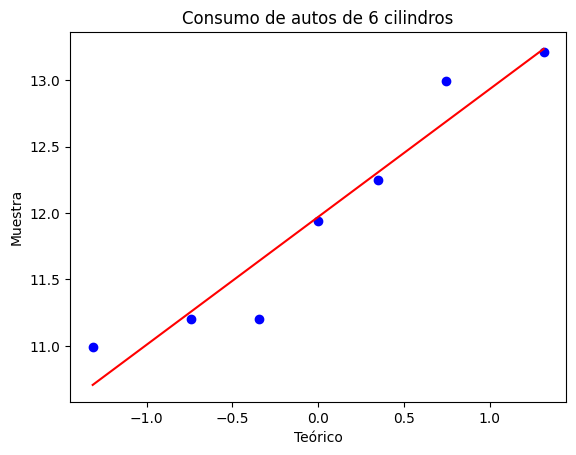

In [9]:
# QQ plot
plt.figure()
stats.probplot(datos, dist="norm", plot=plt)
plt.title("Consumo de autos de 6 cilindros")
plt.xlabel("Teórico")
plt.ylabel("Muestra")
plt.show()

In [13]:
mu0 = 11.7  # Media de la H0

# Valor muestral del Estadístico
t0 = (np.mean(datos) - mu0) / (np.std(datos) / np.sqrt(len(datos)))
pvalor = 1 - stats.t.cdf(t0, df=len(datos) - 1)

print("Valor muestral del Estadístico:", t0)
print("p-valor:", pvalor)
print("Valor medio muestral:", np.mean(datos))


Valor muestral del Estadístico: 0.8622047435288626
p-valor: 0.21084648284832297
Valor medio muestral: 11.970437532892543


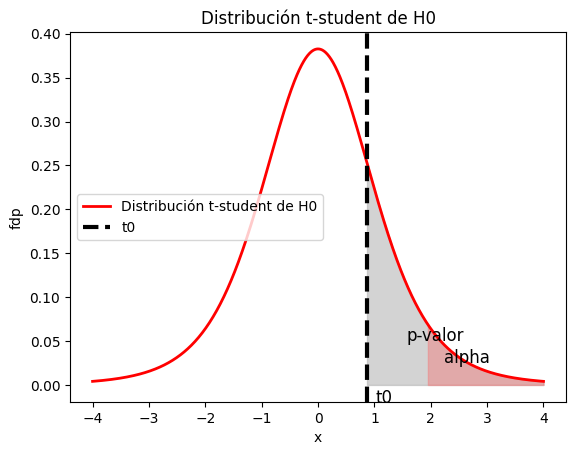

In [11]:
# Gráfico
plt.figure()
x = np.linspace(-4, 4, 1000)
plt.plot(x, stats.t.pdf(x, df=len(datos) - 1), 'r-', lw=2, label="Distribución t-student de H0")
plt.fill_between(x, 0, stats.t.pdf(x, df=len(datos) - 1), where=(x >= t0), color='darkgray', alpha=0.5)
plt.axvline(x=t0, color='black', linestyle='--', lw=3, label='t0')
plt.text(t0 + 0.15, -0.02, 't0', fontsize=12)
plt.text(t0 + 0.7, 0.05, 'p-valor', fontsize=12)
alpha = 0.05
crit = stats.t.ppf(1 - alpha, df=len(datos) - 1)
plt.fill_between(x, 0, stats.t.pdf(x, df=len(datos) - 1), where=(x >= crit), color='lightcoral', alpha=0.5)
plt.text(crit + 0.3, 0.025, 'alpha', fontsize=12)
plt.xlabel("x")
plt.ylabel("fdp")
plt.title("Distribución t-student de H0")
plt.legend()
plt.show()


In [16]:
# T-test
t_statistic, p_value = stats.ttest_1samp(datos, mu0)
print("Valor muestral del Estadístico:", t_statistic)
print("p-valor:", p_value)

Valor muestral del Estadístico: 0.7982464816782587
p-valor: 0.45515246670384
